# Step 2 · 2주차 실습 — 전처리와 특징 추출
sEMG 원신호 → 필터 → 2초 세그먼트 → 200ms 윈도우(50% 오버랩) → 시간영역 특징 5종×5채널(25차원) → 시행 단위 분할 → 표준화 → `dataset.npz`

저장소: https://github.com/starting-stud/sEMG_1012 (`dataset.npz` 포함)

| 제출물 | 위치 |
|---|---|
| ① 필터 검증 | 섹션 2 |
| ② 윈도우 확인 | 섹션 4 |
| ③ `td_features` 전체 | 섹션 5 |
| ④ 분할 코드 (시행 단위 먼저) | 섹션 6 ★ |
| ⑤ 데이터셋 요약 | 섹션 7 |
| ⑥ 설정 근거 | 섹션 9 |

## 0. 설정

In [1]:
import os, subprocess, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from scipy.signal import butter, iirnotch, filtfilt, welch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

REPO = 'https://github.com/TestUser-alt-dev/sEMG-Hand-Gesture-Elbow-Angle-Dataset.git'
REPO_DIR = 'sEMG-Hand-Gesture-Elbow-Angle-Dataset'
if not os.path.exists(REPO_DIR):
    subprocess.run(['git', 'clone', '--depth', '1', REPO, REPO_DIR], check=True)
DATA_DIR = os.path.join(REPO_DIR, 'data')

FS = 1000
plt.rcParams['axes.unicode_minus'] = False
# (한글 폰트가 없는 환경이면 그림 라벨이 깨질 수 있음 — Colab이면 아래 줄 주석 해제)
# !apt-get -qq install fonts-nanum && plt.rcParams['font.family']='NanumGothic'

## 1. 데이터 읽기 — 시행(trial) 단위로 자르기
파일 1개(`a_30 fist.csv` 등)는 **30번 반복을 이어 붙인 연속 기록**이다. `mark` 열이 1인 지점이 시행의 시작이며 시행 하나는 5초(5,000샘플)다.
참가자 8명 × 8조건(동작 4 × 팔꿈치 각도 2) × 30회 = **1,920 시행**.

In [2]:
def load_trials():
    out = []
    for f in sorted(glob.glob(os.path.join(DATA_DIR, '*.csv'))):
        b = os.path.basename(f)[:-4]                # 예: 'a_30 fist'
        subj, ang, g = b[0], int(b[2:4]), b[5:]
        d = pd.read_csv(f)
        x = d.iloc[:, :5].values.astype(float)       # bandpass 1~5 = 5채널
        starts = np.where(d['mark'].values != 0)[0]  # 시행 시작 인덱스(30개)
        for t, s in enumerate(starts):
            out.append(dict(x=x[s:s+5000], subj=subj, angle=ang, gesture=g, trial=t, file=b))
    return out

T = load_trials()
print('전체 시행 수:', len(T), '| 시행 배열 모양:', {t['x'].shape for t in T})

전체 시행 수: 1920 | 시행 배열 모양: {(5000, 5)}


## 2. ① 필터 검증 — 필터 전후 스펙트럼 비교
논문 조건: **60Hz 노치 + 20~450Hz 4차 Butterworth 대역통과**, `filtfilt`(영위상). 노치 Q=30은 실습 설정.

전: [0.0187 0.045  0.0311 0.0111 0.0054]
후: [0.0176 0.0437 0.0304 0.0106 0.0046]
60Hz 부근 PSD 변화(dB): [-5.9 -6.5 -5.6 -5.1 -4.2]
20Hz 미만 파워 비율  전: [0.0071 0.0074 0.0058 0.0287 0.0122]  후: [0.0006 0.0005 0.0006 0.003  0.0013]


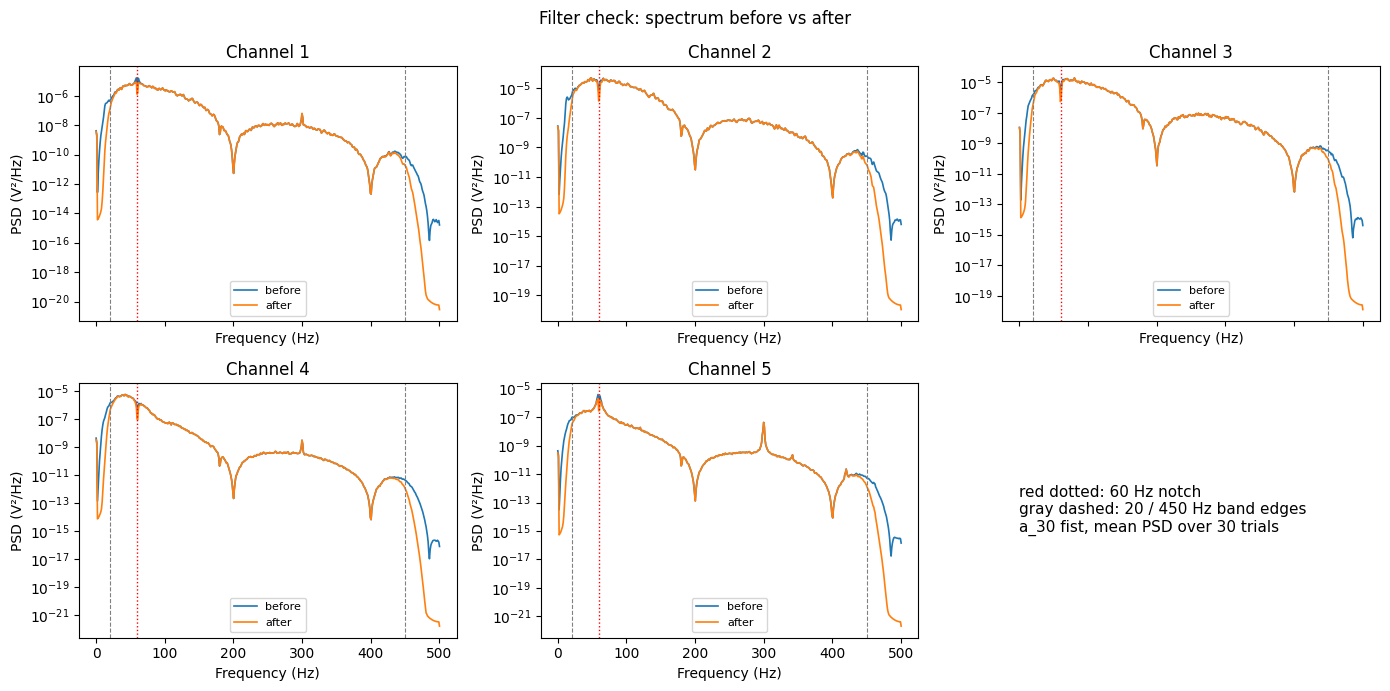

In [3]:
def preprocess(x, fs=FS):
    bn, an = iirnotch(60, 30, fs)
    x = filtfilt(bn, an, x, axis=0)
    b, a = butter(4, [20/(fs/2), 450/(fs/2)], btype='band')
    return filtfilt(b, a, x, axis=0)

sel = [t for t in T if t['file'] == 'a_30 fist']          # 한 조건 30시행
raw = np.stack([t['x'] for t in sel]); flt = np.stack([preprocess(t['x']) for t in sel])

print('전:', raw.reshape(-1, 5).std(0).round(4))
print('후:', flt.reshape(-1, 5).std(0).round(4))

f, Pr = welch(raw, fs=FS, nperseg=1024, axis=1); _, Pf = welch(flt, fs=FS, nperseg=1024, axis=1)
Pr, Pf = Pr.mean(0), Pf.mean(0)
i60 = np.argmin(abs(f - 60))
print('60Hz 부근 PSD 변화(dB):', (10*np.log10(Pf[i60]/Pr[i60])).round(1))
print('20Hz 미만 파워 비율  전:', (Pr[f<20].sum(0)/Pr.sum(0)).round(4), ' 후:', (Pf[f<20].sum(0)/Pf.sum(0)).round(4))

fig, ax = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for c in range(5):
    a = ax.flat[c]
    a.semilogy(f, Pr[:, c], label='before', lw=1.2); a.semilogy(f, Pf[:, c], label='after', lw=1.2)
    a.axvline(60, color='r', ls=':', lw=1); a.axvline(20, color='gray', ls='--', lw=.8); a.axvline(450, color='gray', ls='--', lw=.8)
    a.set_title(f'Channel {c+1}'); a.set_xlabel('Frequency (Hz)'); a.set_ylabel('PSD (V²/Hz)'); a.legend(fontsize=8)
ax.flat[5].axis('off')
ax.flat[5].text(0, .5, 'red dotted: 60 Hz notch\ngray dashed: 20 / 450 Hz band edges\na_30 fist, mean PSD over 30 trials', fontsize=11, va='center')
fig.suptitle('Filter check: spectrum before vs after'); fig.tight_layout(); plt.show()

**해석**: 60Hz에 노치(깊은 골)가 생기고, 20Hz 아래와 450Hz 위가 가파르게 줄어든다.
이 CSV는 컬럼명이 `bandpass`이고 원신호에 이미 대역 필터가 한 번 걸려 있는 듯해서(20Hz 미만이 원래도 적고 450Hz 위가 거의 없음), 필터 전후 차이는 **60Hz 노치와 양 끝 경사**에서 가장 뚜렷하다.

## 3. 분석 구간(2초)의 시작점 정하기
프로토콜은 `휴식 2초 | 동작 1초 | 휴식 2초`지만, 슬라이드의 시작점 1.5초는 **실습 가정**이므로 데이터로 확인한다.
시행마다 신호 파워(RMS 포락선)를 구해 휴식 구간(4.0~4.9초) 기준선보다 확실히 커지는 구간을 동작 구간으로 보고, 2초 창이 그 에너지를 얼마나 담는지 비교했다.

onset  중앙값    963 ms | 5~95% 범위 [ 101. 1396.]
peak   중앙값   1678 ms | 5~95% 범위 [ 975. 2208.]
offset 중앙값   2674 ms | 5~95% 범위 [2024. 3811.]
START=   0  동작 에너지 포착 비율(중앙값) = 0.855
START= 500  동작 에너지 포착 비율(중앙값) = 0.976
START= 800  동작 에너지 포착 비율(중앙값) = 0.987
START=1000  동작 에너지 포착 비율(중앙값) = 0.986
START=1200  동작 에너지 포착 비율(중앙값) = 0.968
START=1500  동작 에너지 포착 비율(중앙값) = 0.827
START=2000  동작 에너지 포착 비율(중앙값) = 0.141


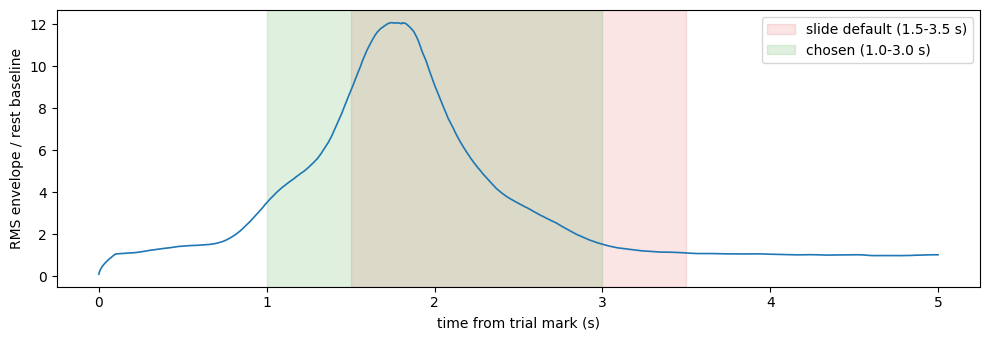

In [4]:
Xall = np.stack([t['x'] for t in T])                       # (1920, 5000, 5)
k = 100
def smooth(a):
    c = np.cumsum(np.pad(a, ((0, 0), (k, 0))), axis=1); return (c[:, k:] - c[:, :-k]) / k
env = np.sqrt(smooth((Xall**2).sum(2)))                    # 시행별 RMS 포락선
base = env[:, 4000:4900]; mu, sd = base.mean(1), base.std(1)

on, off, pk = [], [], []
for i in range(len(env)):
    z = env[i, :4000] > mu[i] + 4*sd[i]
    if z.any():
        idx = np.where(z)[0]
        on.append(idx[0]-k//2); off.append(idx[-1]-k//2); pk.append(env[i, :4000].argmax()-k//2)
for n, a in [('onset', on), ('peak', pk), ('offset', off)]:
    print(f'{n:6s} 중앙값 {np.median(a):6.0f} ms | 5~95% 범위 {np.percentile(a,[5,95]).round(0)}')

E = np.clip(env[:, :4500] - mu[:, None], 0, None)**2
for s in (0, 500, 800, 1000, 1200, 1500, 2000):
    print(f'START={s:4d}  동작 에너지 포착 비율(중앙값) = {np.median(E[:, s:s+2000].sum(1)/E.sum(1)):.3f}')

m = (env/ mu[:, None]).mean(0)
t = np.arange(5000)/FS
plt.figure(figsize=(10, 3.5)); plt.plot(t, m, lw=1.2)
plt.axvspan(1.5, 3.5, color='tab:red', alpha=.12, label='slide default (1.5-3.5 s)')
plt.axvspan(1.0, 3.0, color='tab:green', alpha=.15, label='chosen (1.0-3.0 s)')
plt.xlabel('time from trial mark (s)'); plt.ylabel('RMS envelope / rest baseline'); plt.legend(); plt.tight_layout(); plt.show()

**결정**: `START = 1000`(1.0초부터 2초). 동작 활성이 마크 기준 약 1.0초 즈음에 시작해 약 1.7초에 최대, 약 2.7초에 끝나서, 슬라이드 기본값 1.5초는 앞쪽 활성을 놓친다(에너지 포착 약 83%). 1.0초로 옮기면 약 98.6%를 담는다.

## 4. ② 윈도우 확인 — 배열 모양 출력

In [5]:
START, LEN = 1000, 2000
def cut(x, start=START, n=LEN):
    return x[start:start+n]

WIN, HOP = 200, 100
def make_windows(x, win=WIN, hop=HOP):
    n = (len(x) - win) // hop + 1
    return np.stack([x[i*hop : i*hop+win] for i in range(n)])

seg = cut(preprocess(T[0]['x']))
print('세그먼트 모양:', seg.shape)                  # (2000, 5)
w = make_windows(seg)
print('윈도우 배열:', w.shape)                      # (19, 200, 5)
print('19 = (2000 - 200) / 100 + 1 =', (2000-200)//100 + 1)

세그먼트 모양: (2000, 5)
윈도우 배열: (19, 200, 5)
19 = (2000 - 200) / 100 + 1 = 19


## 5. ③ 특징 구현 — `td_features` 전체
특징 순서(길이 25): `RMS(ch1~5), MAV(ch1~5), WL(ch1~5), ZC(ch1~5), SSC(ch1~5)`

In [6]:
def td_features(w, th=0.01):
    """w: (200, 5) -> (25,)"""
    rms = np.sqrt(np.mean(w**2, axis=0))
    mav = np.mean(np.abs(w), axis=0)
    d   = np.diff(w, axis=0)
    wl  = np.sum(np.abs(d), axis=0)
    zc  = np.sum(((w[:-1]*w[1:]) < 0) &
                 (np.abs(d) >= th), axis=0)
    ssc = np.sum((d[:-1]*d[1:]) < 0, axis=0)
    return np.concatenate([rms, mav, wl, zc, ssc])

feat_names = [f'{fn}_ch{c}' for fn in ['RMS', 'MAV', 'WL', 'ZC', 'SSC'] for c in range(1, 6)]
f0 = td_features(w[0])
print('특징 벡터:', f0.shape)
print('NaN 개수:', np.isnan(f0).sum())
print('ZC 임계값 비교  th=0   :', td_features(w[0], 0.0)[15:20])
print('ZC 임계값 비교  th=0.01:', td_features(w[0], 0.01)[15:20])

특징 벡터: (25,)
NaN 개수: 0
ZC 임계값 비교  th=0   : [20. 25. 30. 16. 22.]
ZC 임계값 비교  th=0.01: [ 4.  8. 12.  5.  0.]


**관찰**: 이 데이터는 진폭이 작아(채널 표준편차 약 0.005~0.045, 단위 V) 임계값 0.01이면 ZC가 `th=0`일 때보다 크게 줄고, 진폭이 작은 채널(예: 채널 5)은 0까지 내려가는 창이 있다. 슬라이드 설정(0.01)을 그대로 따르되, 3주차 결과가 이상하면 이 임계값을 의심 지점으로 둔다.

## 6. ④ 분할 코드 — 시행 단위로 **먼저** 나눈 부분 ★
시행 1,920개를 `train_test_split`으로 **먼저** 나누고(층화: 8클래스), 그 다음 각 집합 안에서만 윈도우·특징을 만든다.
같은 시행에서 나온 겹치는 창 19개는 항상 한쪽에만 들어간다.

In [7]:
cls_names = [f'{g}_{a}' for a in (30, 60) for g in ['fist', 'open', 'pro', 'extor']]
def label_of(t): return cls_names.index(f"{t['gesture']}_{t['angle']}")
labels = np.array([label_of(t) for t in T])
idx = np.arange(len(T))

# ================== ★★★ 분할 (시행 단위, 윈도우 생성보다 먼저) ★★★ ==================
tr_i, te_i = train_test_split(
    idx, test_size=0.2, stratify=labels, random_state=42)
# =====================================================================================

def build(ilist):
    X, y, subj, tid = [], [], [], []
    for i in ilist:
        t = T[i]
        seg = cut(preprocess(t['x']))
        for wnd in make_windows(seg):
            X.append(td_features(wnd)); y.append(labels[i]); subj.append(t['subj']); tid.append(i)
    return np.stack(X), np.array(y), np.array(subj), np.array(tid)

Xtr, ytr, subj_tr, trial_tr = build(tr_i)
Xte, yte, subj_te, trial_te = build(te_i)
print(Xtr.shape, Xte.shape, '| 학습/테스트 비율 = %.2f' % (len(Xtr)/len(Xte)))

# 누수 점검: 학습·테스트에 같은 시행이 들어갔는가?
overlap = set(trial_tr) & set(trial_te)
print('학습·테스트 공통 시행 수:', len(overlap))
assert len(overlap) == 0

(29184, 25) (7296, 25) | 학습/테스트 비율 = 4.00
학습·테스트 공통 시행 수: 0


## 7. ⑤ 데이터셋 요약

In [8]:
ctr, cte = Counter(ytr), Counter(yte)
summ = pd.DataFrame({
    '클래스': cls_names,
    '학습 시행': [ctr[k]//19 for k in range(8)], '학습 윈도우': [ctr[k] for k in range(8)],
    '테스트 시행': [cte[k]//19 for k in range(8)], '테스트 윈도우': [cte[k] for k in range(8)]})
summ.loc[len(summ)] = ['합계', len(tr_i), len(Xtr), len(te_i), len(Xte)]
display(summ)
print('특징 차원:', Xtr.shape[1], '| NaN:', np.isnan(Xtr).sum() + np.isnan(Xte).sum())
print('참가자별 시행 수  학습:', {str(k): v for k, v in sorted(Counter(subj_tr[::19]).items())})
print('참가자별 시행 수  테스트:', {str(k): v for k, v in sorted(Counter(subj_te[::19]).items())})

,클래스,학습 시행,학습 윈도우,테스트 시행,테스트 윈도우
0,fist_30,192,3648,48,912
1,open_30,192,3648,48,912
2,pro_30,192,3648,48,912
3,extor_30,192,3648,48,912
4,fist_60,192,3648,48,912
5,open_60,192,3648,48,912
6,pro_60,192,3648,48,912
7,extor_60,192,3648,48,912
8,합계,1536,29184,384,7296


특징 차원: 25 | NaN: 0
참가자별 시행 수  학습: {'a': 183, 'b': 198, 'c': 200, 'd': 191, 'e': 185, 'f': 181, 'g': 203, 'h': 195}
참가자별 시행 수  테스트: {'a': 57, 'b': 42, 'c': 40, 'd': 49, 'e': 55, 'f': 59, 'g': 37, 'h': 45}


## 8. 표준화와 저장

In [9]:
sc = StandardScaler()
Xtr_s = sc.fit_transform(Xtr)      # 학습셋에서만 fit
Xte_s = sc.transform(Xte)          # 테스트엔 적용만

print('학습셋 평균 |최대|:', np.abs(Xtr_s.mean(0)).max().round(6), '| 표준편차 최소/최대:', Xtr_s.std(0).min().round(4), Xtr_s.std(0).max().round(4))
print('테스트셋 평균 범위:', Xte_s.mean(0).min().round(3), Xte_s.mean(0).max().round(3),
      '| 표준편차 범위:', Xte_s.std(0).min().round(3), Xte_s.std(0).max().round(3))

np.savez('dataset.npz', Xtr=Xtr_s, ytr=ytr, Xte=Xte_s, yte=yte,
         subj_tr=subj_tr, subj_te=subj_te, trial_tr=trial_tr, trial_te=trial_te,
         class_names=np.array(cls_names), feature_names=np.array(feat_names),
         scaler_mean=sc.mean_, scaler_scale=sc.scale_)
print('저장 완료:', os.path.getsize('dataset.npz')//1024, 'KB')

학습셋 평균 |최대|: 0.0 | 표준편차 최소/최대: 1.0 1.0
테스트셋 평균 범위: -0.053 0.081 | 표준편차 범위: 0.908 1.084
저장 완료: 7841 KB


`dataset.npz` 키: `Xtr, ytr, Xte, yte`(과제 요구) + 추가 정보 `subj_*`(참가자), `trial_*`(시행 ID), `class_names`, `feature_names`, `scaler_mean`, `scaler_scale`.

## 9. ⑥ 설정 근거
**윈도우 200ms** — 200ms(200샘플)는 근전도를 짧은 구간 안에서는 대략 안정적인 신호로 볼 수 있을 만큼 짧으면서도, RMS·ZC·SSC 같은 통계량이 흔들리지 않을 만큼의 샘플을 담는다. 또 실시간 제어에서 허용 지연으로 흔히 인용되는 300ms 이내여서, 이후 실시간 적용을 생각해도 부담이 없는 길이다.

**오버랩 50%** — 겹치지 않게 자르면 2초에서 10개뿐이지만 100ms씩 밀면 19개가 나와 같은 신호에서 시간 해상도와 샘플 수를 거의 두 배로 얻는다. 대신 이웃한 창이 같은 신호를 공유해 서로 독립이 아니므로, 반드시 시행 단위로 먼저 분할해야 누수가 생기지 않는다.

## 10. 특이사항 메모
- 시행 시작은 `mark` 열로 구분했다. 일부 파일은 시행 간격이 5,000이 아니라 4,999~5,001샘플이라 `mark` 위치부터 5,000샘플씩 잘랐다(마지막 시행 뒤에도 5,700샘플 이상 남아 잘림 없음).
- 분석 구간 시작을 슬라이드 가정(1.5초)에서 **1.0초**로 바꿨다(섹션 3의 근거).
- 분할은 클래스(8종) 층화 기준이며, 참가자 정보는 `dataset.npz`에 따로 담아 두었다(3주차 이후 참가자별 평가 등에 사용 가능).